# Data Science Mini Project: What Affects Student Performance?

**Dataset:** `student_performance.csv` (500 students, 11 columns)
**Source:** *(add the Kaggle or provider link and licence here)*
**Question:** Which factors are linked to students passing, and how strongly?

**Method:** load the data, check its quality, clean it, compare groups, measure correlations, and visualise the results.

**Limitation to note:** `passed` is defined as a final score of 50 or more in this file, so the pass rate restates the final score rather than measuring a separate outcome.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Libraries loaded")

Libraries loaded


## 2. Load the data

`keep_default_na=False` stops the text `None` (no parental education) from being read as a missing value.

In [2]:
df = pd.read_csv("student_performance.csv", keep_default_na=False, na_values=[""])
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (500, 11)


,student_id,gender,age,study_hours_per_week,attendance_rate,parent_education,internet_access,extracurricular,previous_score,final_score,passed
0,STU0001,Male,15,25,63.8,Bachelor,Yes,Yes,41,67,Yes
1,STU0002,Female,15,2,54.7,Bachelor,Yes,Yes,83,28,No
2,STU0003,Female,19,10,90.5,High School,Yes,No,73,49,No
3,STU0004,Male,16,26,66.8,High School,No,Yes,75,70,Yes
4,STU0005,Female,15,25,73.0,High School,No,Yes,67,77,Yes


## 3. Understand the data

In [3]:
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            500 non-null    str    
 1   gender                500 non-null    str    
 2   age                   500 non-null    int64  
 3   study_hours_per_week  500 non-null    int64  
 4   attendance_rate       500 non-null    float64
 5   parent_education      500 non-null    str    
 6   internet_access       500 non-null    str    
 7   extracurricular       500 non-null    str    
 8   previous_score        500 non-null    int64  
 9   final_score           500 non-null    int64  
 10  passed                500 non-null    str    
dtypes: float64(1), int64(4), str(6)
memory usage: 43.1 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,500,500,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,500,2,Female,273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,500.0,NaN,NaN,NaN,16.978,1.434445,15.0,16.0,17.0,18.0,19.0
study_hours_per_week,500.0,NaN,NaN,NaN,15.312,8.568167,2.0,8.0,15.0,23.0,30.0
attendance_rate,500.0,NaN,NaN,NaN,76.3806,13.817681,50.2,64.475,76.5,88.525,100.0
parent_education,500,5,None,117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internet_access,500,2,Yes,254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
extracurricular,500,2,No,253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
previous_score,500.0,NaN,NaN,NaN,62.986,18.937451,30.0,46.0,64.0,79.0,95.0
final_score,500.0,NaN,NaN,NaN,55.98,15.373754,20.0,45.0,56.0,68.0,95.0


## 4. Quality checks

In [4]:
print("Missing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate student IDs:", df["student_id"].duplicated().sum())
print("\nparent_education categories:", df["parent_education"].value_counts().to_dict())

Missing values:
 student_id              0
gender                  0
age                     0
study_hours_per_week    0
attendance_rate         0
parent_education        0
internet_access         0
extracurricular         0
previous_score          0
final_score             0
passed                  0
dtype: int64

Duplicate rows: 0
Duplicate student IDs: 0

parent_education categories: {'None': 117, 'Master': 100, 'Bachelor': 97, 'High School': 95, 'PhD': 91}


## 5. Cleaning and new features

- Remove duplicates and standardise column names.
- Fill any gaps (there are none in this file, but the step keeps the notebook reusable).
- Create a 0/1 pass flag, the change between previous and final score, and grouped versions of attendance and study hours.

In [5]:
df = df.drop_duplicates()
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

for c in df.select_dtypes(include="number").columns:
    df[c] = df[c].fillna(df[c].median())
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].fillna(df[c].mode()[0])

df["passed_flag"] = (df["passed"].str.strip().str.lower() == "yes").astype(int)
df["score_change"] = df["final_score"] - df["previous_score"]
df["attendance_group"] = pd.cut(df["attendance_rate"], bins=[0, 60, 75, 90, 100],
                                labels=["<60", "60-75", "75-90", "90+"])
df["study_group"] = pd.cut(df["study_hours_per_week"], bins=[0, 5, 15, 25, 100],
                           labels=["0-5", "6-15", "16-25", "26+"])

df[["final_score", "passed", "passed_flag", "score_change", "study_group"]].head()

,final_score,passed,passed_flag,score_change,study_group
0,67,Yes,1,26,16-25
1,28,No,0,-55,0-5
2,49,No,0,-24,6-15
3,70,Yes,1,-5,26+
4,77,Yes,1,10,16-25


## 6. Overall picture

In [6]:
print("Overall pass rate (%):", round(df["passed_flag"].mean() * 100, 1))
print("Average final score:", round(df["final_score"].mean(), 1))
print("Average score change (final minus previous):", round(df["score_change"].mean(), 1))
print("Share of students whose score improved (%):", round((df["score_change"] > 0).mean() * 100, 1))

Overall pass rate (%): 64.6
Average final score: 56.0
Average score change (final minus previous): -7.0
Share of students whose score improved (%): 36.8


## 7. Compare groups

The pass rate for each group, as a percentage.

In [7]:
print("Pass rate (%) by study hours:")
print(df.groupby("study_group", observed=True)["passed_flag"].mean().mul(100).round(1))

print("\nPass rate (%) by attendance:")
print(df.groupby("attendance_group", observed=True)["passed_flag"].mean().mul(100).round(1))

print("\nPass rate (%) by parent education:")
print(df.groupby("parent_education")["passed_flag"].mean().mul(100).round(1).sort_values())

for col in ["gender", "internet_access", "extracurricular"]:
    print(f"\nPass rate (%) by {col}:")
    print(df.groupby(col)["passed_flag"].mean().mul(100).round(1))

Pass rate (%) by study hours:
study_group
0-5       18.8
6-15      45.5
16-25     92.4
26+      100.0
Name: passed_flag, dtype: float64

Pass rate (%) by attendance:
attendance_group
<60      54.9
60-75    60.5
75-90    66.9
90+      74.5
Name: passed_flag, dtype: float64

Pass rate (%) by parent education:
parent_education
Bachelor       53.6
PhD            64.8
None           66.7
Master         67.0
High School    70.5
Name: passed_flag, dtype: float64

Pass rate (%) by gender:
gender
Female    63.7
Male      65.6
Name: passed_flag, dtype: float64

Pass rate (%) by internet_access:
internet_access
No     63.4
Yes    65.7
Name: passed_flag, dtype: float64

Pass rate (%) by extracurricular:
extracurricular
No     63.2
Yes    66.0
Name: passed_flag, dtype: float64


## 8. Correlations

A value near +1 or −1 means a strong straight-line relationship. A value near 0 means little relationship. Correlation does not show cause.

In [8]:
num_cols = ["age", "study_hours_per_week", "attendance_rate", "previous_score", "final_score"]
corr = df[num_cols].corr().round(2)
corr

,age,study_hours_per_week,attendance_rate,previous_score,final_score
age,1.00,-0.06,0.03,-0.11,-0.05
study_hours_per_week,-0.06,1.00,-0.02,-0.08,0.80
attendance_rate,0.03,-0.02,1.00,-0.03,0.24
previous_score,-0.11,-0.08,-0.03,1.00,0.16
final_score,-0.05,0.80,0.24,0.16,1.00


## 9. Visualisations

**Chart 1: Score distributions.** Shows how scores are spread across students.

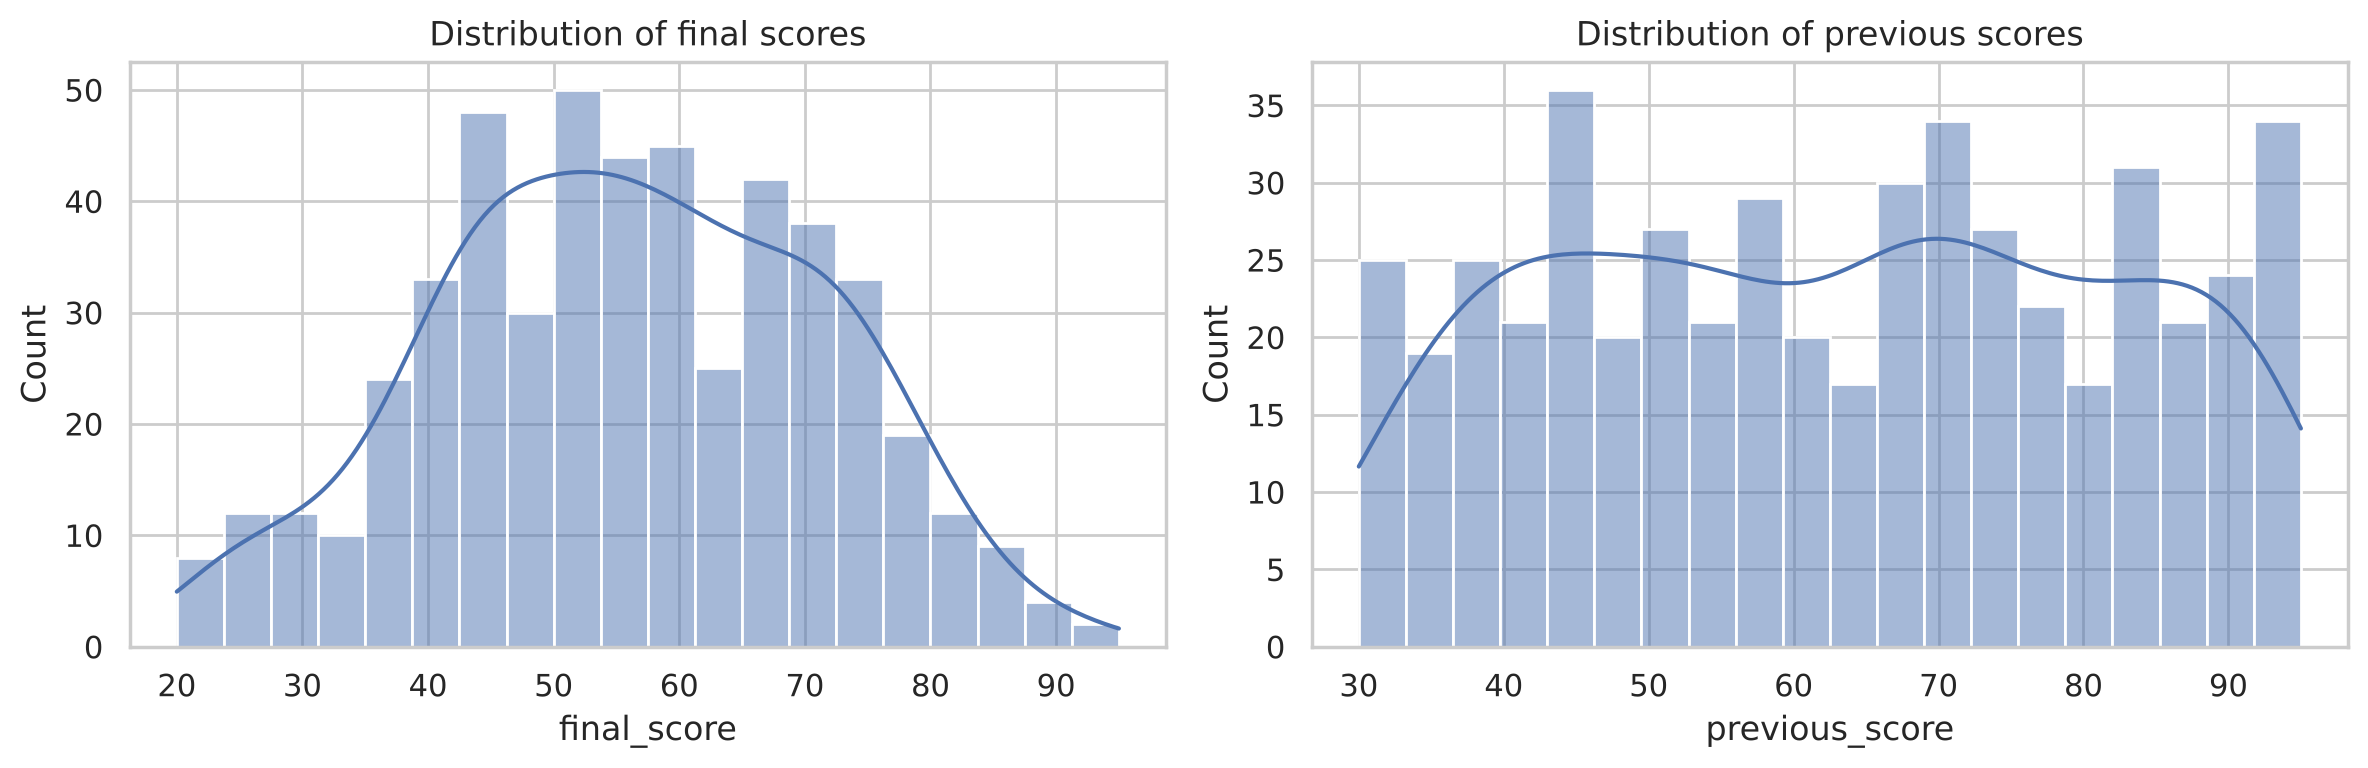

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["final_score"], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Distribution of final scores")
sns.histplot(df["previous_score"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Distribution of previous scores")
plt.tight_layout()
plt.show()

**Chart 2: Pass rate by study hours.** The strongest pattern in the data.

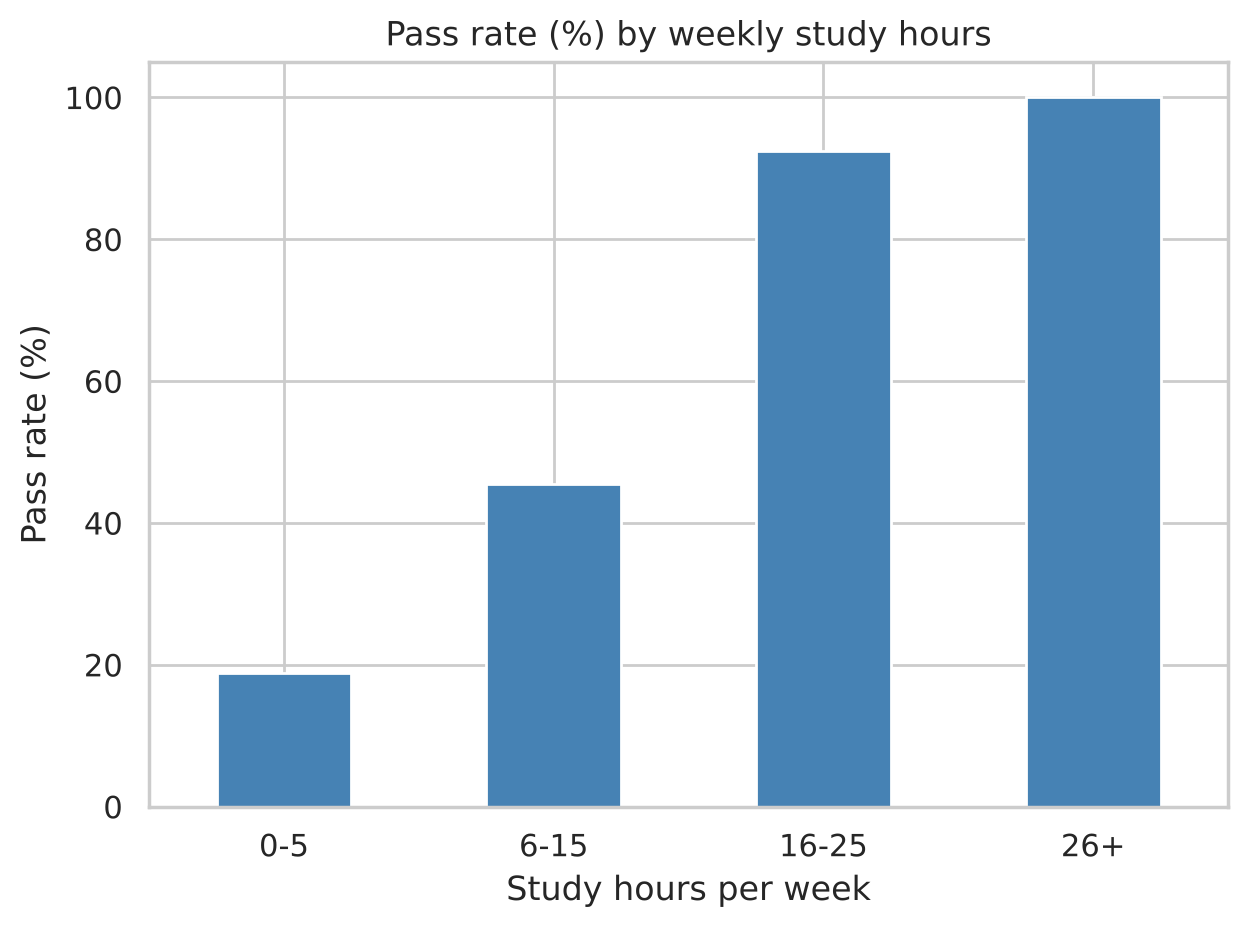

In [10]:
study_pass = df.groupby("study_group", observed=True)["passed_flag"].mean().mul(100)
study_pass.plot(kind="bar", color="steelblue")
plt.title("Pass rate (%) by weekly study hours")
plt.ylabel("Pass rate (%)")
plt.xlabel("Study hours per week")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chart 3: Study hours vs final score.** Each dot is one student. The dashed line is the pass mark of 50.

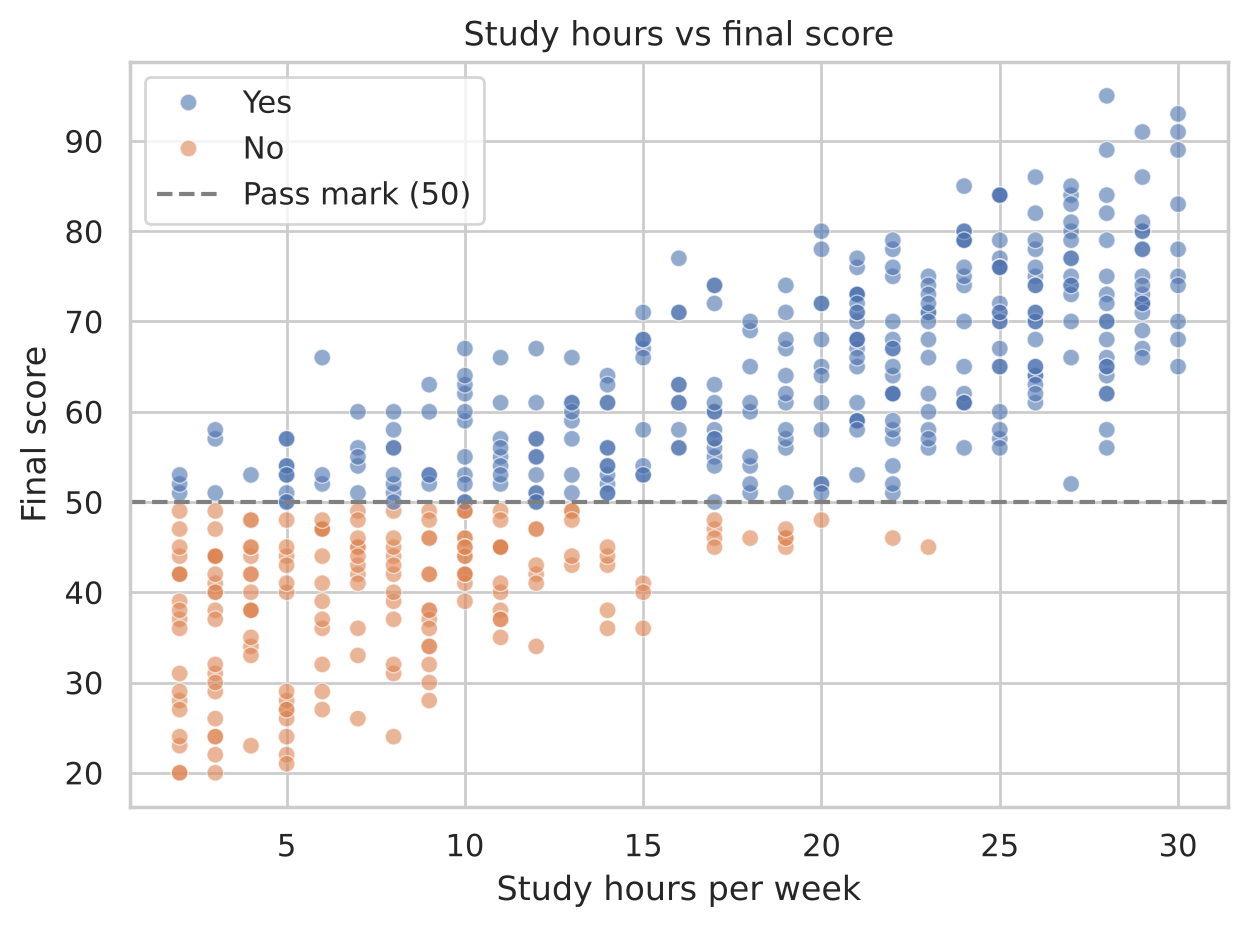

In [11]:
sns.scatterplot(data=df, x="study_hours_per_week", y="final_score", hue="passed", alpha=0.6)
plt.axhline(50, color="grey", linestyle="--", label="Pass mark (50)")
plt.title("Study hours vs final score")
plt.xlabel("Study hours per week")
plt.ylabel("Final score")
plt.legend()
plt.tight_layout()
plt.show()

**Chart 4: Final score by attendance group.** Shows the spread of scores, not only the pass rate.

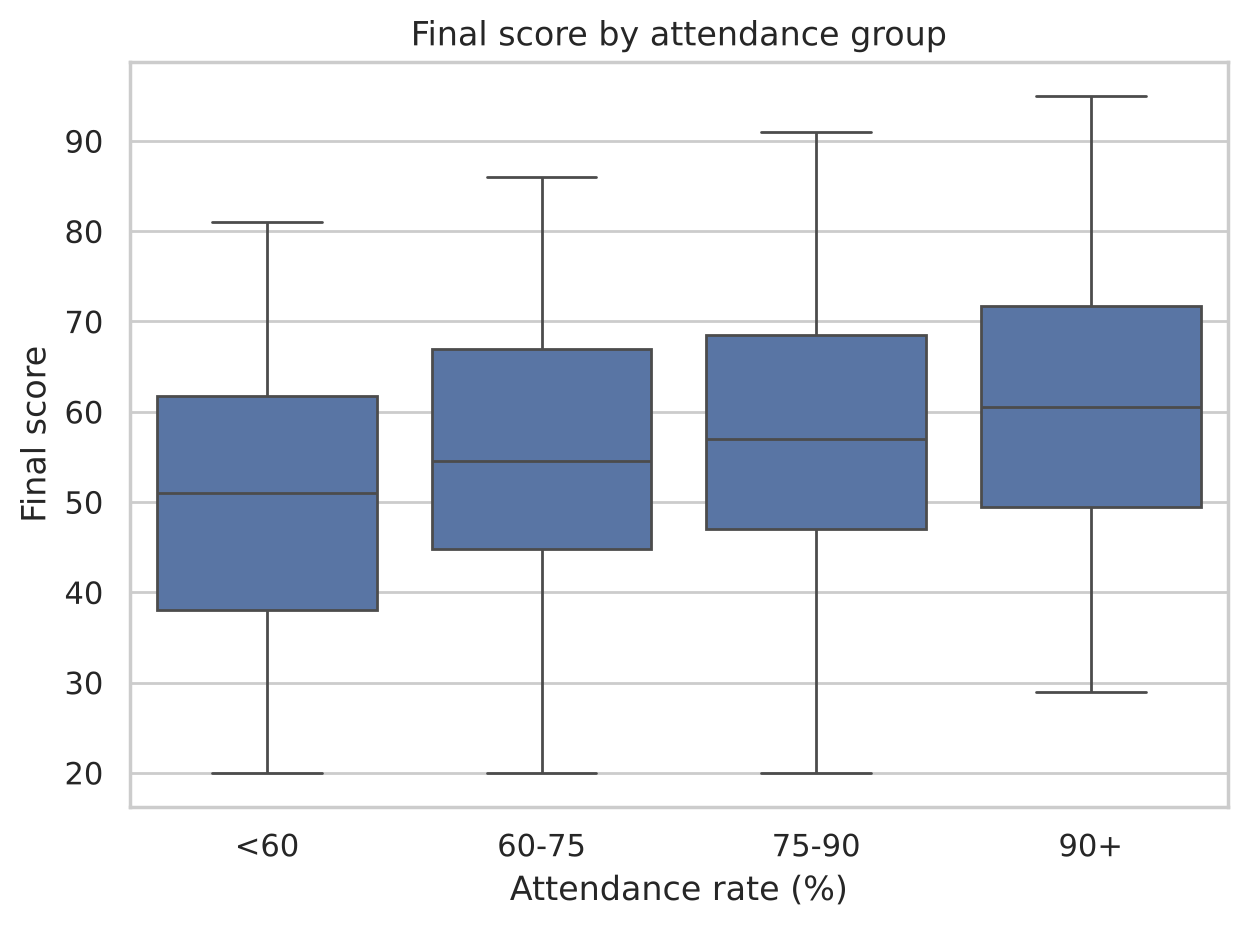

In [12]:
sns.boxplot(data=df, x="attendance_group", y="final_score")
plt.title("Final score by attendance group")
plt.xlabel("Attendance rate (%)")
plt.ylabel("Final score")
plt.tight_layout()
plt.show()

**Chart 5: Pass rate by parent education.** Each group has about 100 students, so treat small differences with caution.

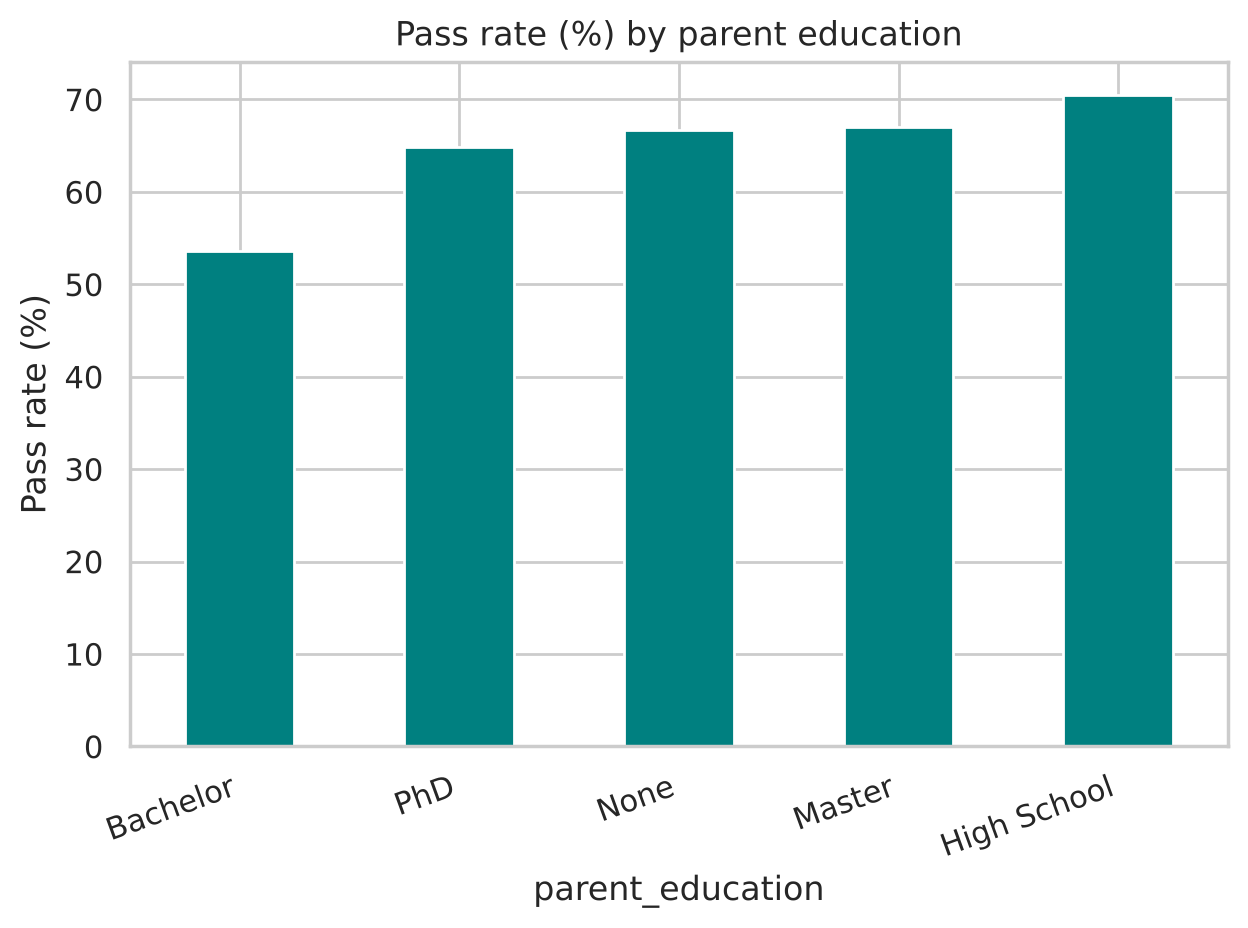

In [13]:
df.groupby("parent_education")["passed_flag"].mean().mul(100).sort_values().plot(kind="bar", color="teal")
plt.title("Pass rate (%) by parent education")
plt.ylabel("Pass rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Chart 6: Correlation heatmap.** All correlations from Section 8 in one view.

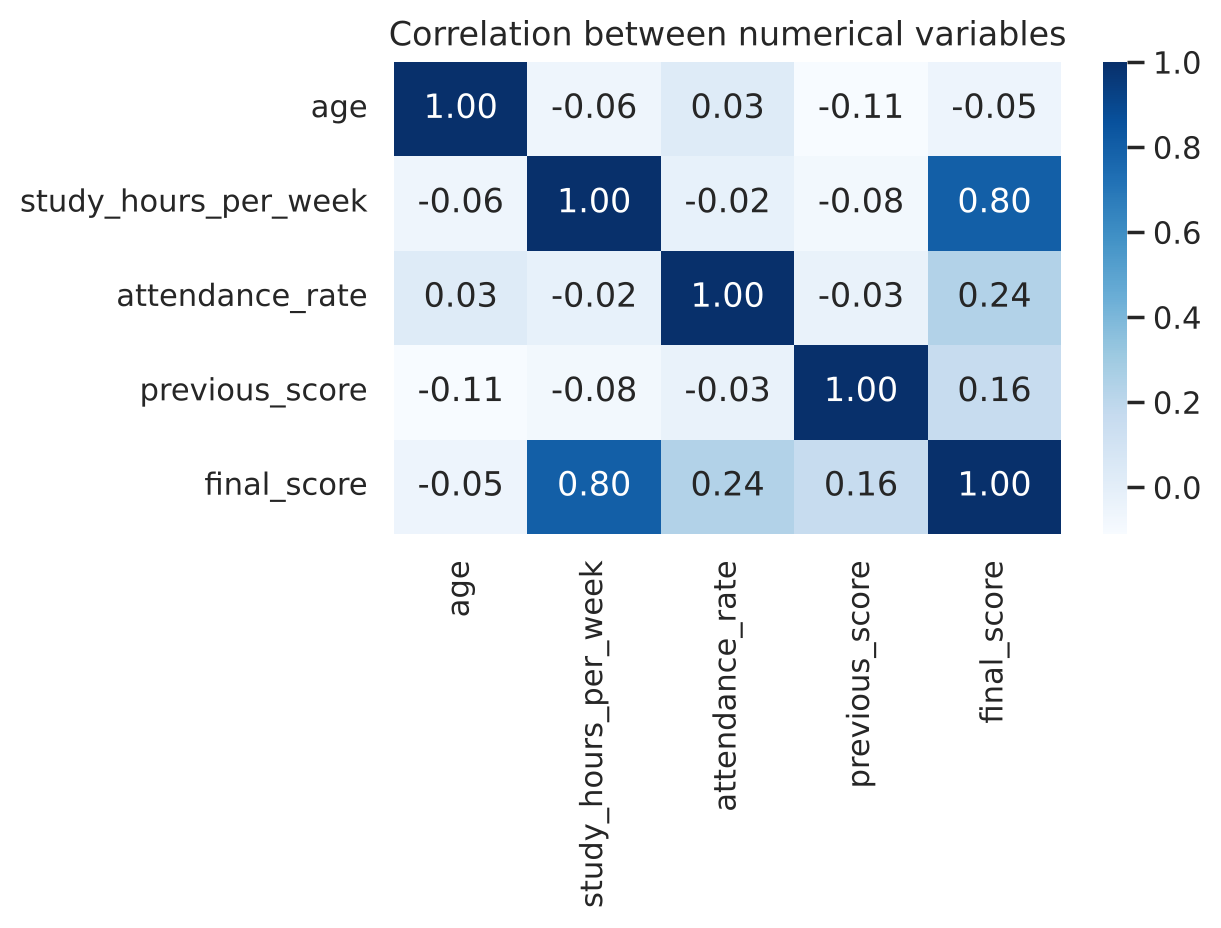

In [14]:
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation between numerical variables")
plt.tight_layout()
plt.show()

## 10. Machine learning

Two models answer two questions:

- **Regression:** can we predict a student's **final score** from information available before the exam?
- **Classification:** can we predict whether a student will **pass**?

**Leakage check.** `final_score`, `score_change`, `passed` and `passed_flag` are not used as inputs, because they are derived from the outcome. The grouped columns are also left out, since they repeat the numeric columns.

Every model is compared with a simple baseline. A model is only useful if it beats the baseline on data it has not seen.

In [15]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             accuracy_score, roc_auc_score, ConfusionMatrixDisplay)

categorical = ["gender", "parent_education", "internet_access", "extracurricular"]
numeric = ["age", "study_hours_per_week", "attendance_rate", "previous_score"]
X = df[categorical + numeric]

def make_preprocessor(scale_numeric):
    """Encode categories as 0/1 columns. Scale numbers only for linear models."""
    return ColumnTransformer([
        ("num", StandardScaler() if scale_numeric else "passthrough", numeric),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
    ])

print("Inputs:", X.shape[1], "columns,", X.shape[0], "students")
print("Excluded (derived from the outcome): final_score, score_change, passed, passed_flag")

Inputs: 8 columns, 500 students
Excluded (derived from the outcome): final_score, score_change, passed, passed_flag


### 10.1 Regression: predict the final score

The data is split 80% for training and 20% for testing. The test set is never used for fitting.

In [16]:
y_reg = df["final_score"]
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

reg_models = {
    "Baseline (always predict the average)": Pipeline([("prep", make_preprocessor(False)), ("model", DummyRegressor(strategy="mean"))]),
    "Linear regression": Pipeline([("prep", make_preprocessor(True)), ("model", LinearRegression())]),
    "Random forest": Pipeline([("prep", make_preprocessor(False)), ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42))]),
}

rows = []
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"Model": name,
                 "MAE (points)": mean_absolute_error(y_test, pred),
                 "RMSE (points)": root_mean_squared_error(y_test, pred),
                 "R²": r2_score(y_test, pred)})

reg_results = pd.DataFrame(rows).round(2)
reg_results

,Model,MAE (points),RMSE (points),R²
0,Baseline (always predict the average),12.34,14.76,-0.00
1,Linear regression,6.25,7.29,0.76
2,Random forest,6.93,8.27,0.68


**How to read this table.** MAE is the average miss in points, so a lower value is better. R² is the share of score variation explained by the model, where 0 means no better than the average and 1 means perfect.

### 10.2 Classification: predict pass or fail

The split keeps the pass/fail ratio the same in both sets (`stratify`).

In [17]:
y_cls = df["passed_flag"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

clf_models = {
    "Baseline (always predict the most common result)": Pipeline([("prep", make_preprocessor(False)), ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("prep", make_preprocessor(True)), ("model", LogisticRegression(max_iter=1000))]),
    "Random forest": Pipeline([("prep", make_preprocessor(False)), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42))]),
}

rows = []
for name, model in clf_models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    proba = model.predict_proba(Xc_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yc_test, pred),
                 "ROC AUC": roc_auc_score(yc_test, proba)})

clf_results = pd.DataFrame(rows).round(3)
clf_results

,Model,Accuracy,ROC AUC
0,Baseline (always predict the most common result),0.65,0.500
1,Logistic regression,0.84,0.941
2,Random forest,0.87,0.936


**How to read this table.** Accuracy is the share of correct predictions. ROC AUC measures how well the model ranks passing students above failing ones: 0.5 is chance and 1.0 is perfect. The baseline's AUC is 0.5 by design.

**Confusion matrix** for the random forest on the test set: how many passes and fails were predicted correctly.

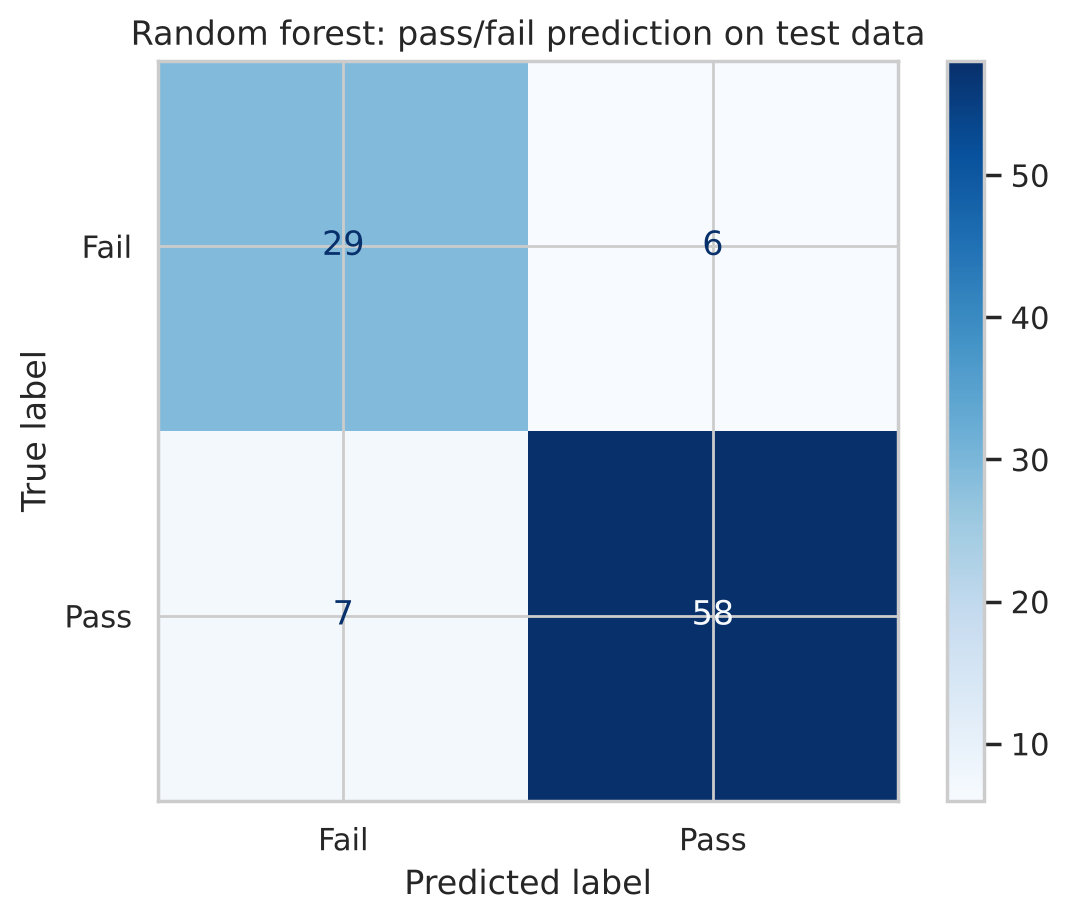

In [18]:
rf_clf = clf_models["Random forest"]
ConfusionMatrixDisplay.from_estimator(rf_clf, Xc_test, yc_test,
                                      display_labels=["Fail", "Pass"], cmap="Blues")
plt.title("Random forest: pass/fail prediction on test data")
plt.show()

### 10.3 Checking stability and what drives the predictions

A single split can be lucky. Five-fold cross-validation trains and tests on five different splits, so the score is more reliable.

In [19]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(reg_models["Random forest"], X, y_reg, cv=kf, scoring="r2")
print("Random forest, 5-fold cross-validation R²:")
print("  per fold:", np.round(cv_r2, 3))
print(f"  mean: {cv_r2.mean():.3f}  (± {cv_r2.std():.3f})")

Random forest, 5-fold cross-validation R²:
  per fold: [0.688 0.724 0.71  0.691 0.731]
  mean: 0.709  (± 0.017)


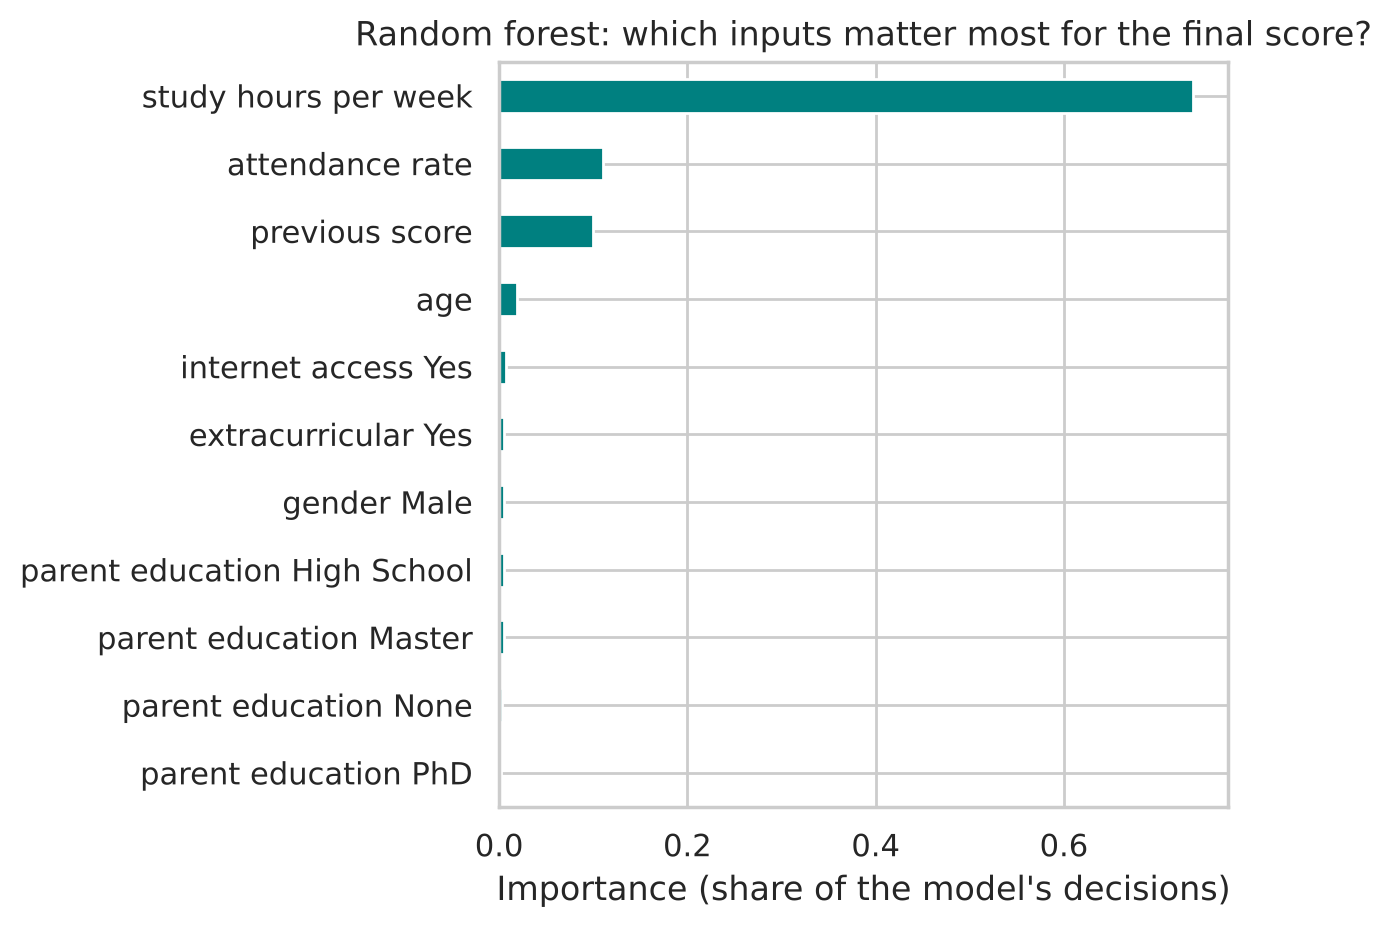

study hours per week            0.737
attendance rate                 0.110
previous score                  0.100
age                             0.019
internet access Yes             0.007
extracurricular Yes             0.006
gender Male                     0.005
parent education High School    0.005
parent education Master         0.005
parent education None           0.003
parent education PhD            0.002
dtype: float64

In [20]:
rf_reg = reg_models["Random forest"]
names = (rf_reg.named_steps["prep"].get_feature_names_out()
         .astype(str))
names = [n.replace("num__", "").replace("cat__", "").replace("_", " ") for n in names]
importance = pd.Series(rf_reg.named_steps["model"].feature_importances_, index=names).sort_values()

importance.plot(kind="barh", color="teal")
plt.title("Random forest: which inputs matter most for the final score?")
plt.xlabel("Importance (share of the model's decisions)")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(3)

**Model choice.** The linear regression had the best test-set R² (0.76) and is the easiest to explain. The random forest reached a cross-validated R² of 0.71, so the two models perform similarly. For pass/fail, the random forest and logistic regression are close (ROC AUC about 0.94).

Study hours dominate the random forest's decisions. This matches the correlation in Section 8.

### 10.4 Try the model on a new student

Change the values below to see the predicted final score. This is a prediction from one model, not a guarantee.

In [21]:
new_student = pd.DataFrame([{
    "gender": "Female", "parent_education": "Bachelor", "internet_access": "Yes", "extracurricular": "No",
    "age": 16, "study_hours_per_week": 20, "attendance_rate": 85.0, "previous_score": 60,
}])
predicted = rf_reg.predict(new_student)[0]
print(f"Predicted final score: {predicted:.1f}")
print("Predicted result:", "Pass" if predicted >= 50 else "Fail", "(pass mark = 50, as in this dataset)")

Predicted final score: 69.3
Predicted result: Pass (pass mark = 50, as in this dataset)


## 11. Key findings

1. **Study hours are the strongest factor.** The pass rate rises from 18.8% (0–5 hours) to 100% (26+ hours). Study hours correlate with final score at 0.80.
2. **Attendance has a consistent positive link.** The pass rate rises from 54.9% (below 60%) to 74.5% (90% and above).
3. **Previous score and age have weak or no link** with final score (0.16 and −0.05).
4. **Scores fell on average.** Final scores were about 7 points lower than previous scores, and only 36.8% of students improved.
5. **Gender, internet access and extracurricular activity make little difference** (1–3 points).
6. **Parent education shows a weak pattern** (53.6% to 70.5%). The groups are of similar size and small, so this is not conclusive.
7. **Machine learning confirms the pattern.** A linear model predicts the final score within about 6 points on average (test R² 0.76, against 0.00 for the baseline). Pass/fail prediction reaches 84–87% accuracy, against 65% for the baseline.
8. **Study hours matter most** for the prediction, with about three-quarters of the random forest's importance. Attendance and previous score come next.

## 11. Limitations

- `passed` equals "final score ≥ 50" in this file, so it is not an independent outcome.
- Correlations show association, not cause.
- Parent-education groups are of modest size, and the data does not say how it was collected.
- The dataset is a single snapshot, so changes over time cannot be measured.
- The models use 400 training students. They have not been tested on data from another school or year, so they should not be used to judge individual students.
- Predicting the final score from pre-exam information is a useful check, but the real test would be a model trained on earlier cohorts and tested on later ones.

## 12. Save the cleaned data

In [22]:
df.to_csv("cleaned_student_performance.csv", index=False)
print("Saved cleaned_student_performance.csv with", df.shape[0], "rows")

Saved cleaned_student_performance.csv with 500 rows
